# BSISO vs MISO: active/break spells and extreme rain (EREs) over central India

Two indices of the monsoon's intraseasonal swings are compared:
- **BSISO1** (Lee et al. 2013, APCC): built from OLR and 850 hPa wind over 10°S-40°N, 40-160°E.
- **MISO** (Suhas et al. 2013; official IITM index): built from the last 15 days of rain over the Indian region.

Questions:
1. How well does each index **forecast itself**?
2. How well does each index **forecast EREs**?
3. **When** does each index know about an ERE or a spell?
4. How do spells and EREs **cluster** in each index's phase diagram?

**EREs** (0.25°, as in the rest of this repo): at least one 8-connected cluster of 16 or more IMERG cells, each above
its own wet-day 99th percentile, centred in central India. Size classes: 16-39, 40-90 and 91+ cells.

**Spells:** standardised central-India rain ≥ +1 sd (active) or ≤ -1 sd (break) for at least 3 days, in JJAS.

**Days:** JJAS 2000-2020, because the MISO files stop in October 2020.

The forecast comparison (section 4) was trained on a Kaggle GPU (`code/kaggle_BSISO_Tests_R8.py`). Here its result
tables (`results/`) are read and plotted. Sections 1-3 run locally from the data.

In [1]:
# settings: point PROJ at the folder that holds data/ (BSISO index, IMERG, India mask, official_indices/miso_iitm)
# and Summer_26/Other/derived/spell_drivers_daily.csv
import os
PROJ = os.environ.get("PROJ", r"C:\Users\divya\OneDrive\Desktop\IIT- Bombay Summer 26\Moaap\Regional_claude")
HERE = os.getcwd()
CODE, RESULTS, FIGURES = (os.path.join(HERE, d) for d in ("code", "results", "figures"))
from IPython.display import Image, display

## 1. When does each index know about an ERE? (observed indices, no forecast)

Rain skill (RPSS) when the observed index is taken k days before (+) or after (-) the target day.

In [2]:
# R8 follow-up: observed index taken from 14 days AFTER to 10 days BEFORE the target day (negative lag = after).
# Built from R8_local_index_ceiling.py (same days, same rain step). Output: R8_miso/ceiling/lead_lag_minus14_to_10.csv
# R8 (local, CPU): the rain-step CEILING of each index. Observed (perfectly known) BSISO1 vs observed MISO (IITM,
# Suhas et al. 2013) at lags 0-10 days before the target day -> daily 4-class ERE chances in central India.
# Same rain step as the final package (cumulative logistic + smoothed normal chance, leave-one-year-out).
# Same days for every input: JJAS target days 2000-2020 (the official MISO files stop in Oct 2020).
# Pre-registered rule: each index's lag for the forecast round = the lag with the highest observed RPSS here.
import os, re, glob
import numpy as np, pandas as pd

SP7 = os.path.join(PROJ, "sem_project_7")
OUTT = RESULTS
os.makedirs(OUTT, exist_ok=True)
os.environ["BSISO_DATA"] = os.path.join(PROJ, "data"); os.environ["FAST"] = "1"
src = open(os.path.join(CODE, "BSISO_daily_ERE_Prediction.py"), encoding="utf-8").read()
cells = {blk.split(" --")[0].strip(): blk for blk in re.split(r"^# %% ", src, flags=re.M)[1:] if not blk.startswith("MD")}
ns = {"__name__": "__main__", "display": lambda *a: None}
os.chdir(os.environ.get("TEMP", "."))
exec(compile("# " + cells["CELL 1"], "c1", "exec"), ns)
exec(compile("# " + cells["CELL 2"], "c2", "exec"), ns)         # data, ERE days (needs torch only for the device)
c7 =cells["CELL 7"].split("YC = [")[0]
c7 = c7.replace("FCI = {nm: pd.DataFrame(FC[nm].reshape(len(ISSUE), -1), index=ISSUE) for nm in MODELS}", "")
exec(compile("# " + c7, "c7", "exec"), ns)
b, times, years, kidx, ND, CLS4, OBS1 = (ns[k] for k in ("b", "times", "years", "kidx", "ND", "CLS4", "OBS1"))
ordinal_eval = ns["ordinal_eval"]


def load_miso():
    rows = []
    for f in sorted(glob.glob(os.path.join(PROJ, "data", "official_indices", "miso_iitm", "*_pc_MJJASO.dat"))):
        a = np.loadtxt(f)
        d = pd.Timestamp(int(os.path.basename(f)[:4]), 5, 1) + pd.to_timedelta(a[:, 0] - 1, "D")
        rows.append(pd.DataFrame({"m1": a[:, 1], "m2": a[:, 2]}, index=d))
    return pd.concat(rows).asfreq("D")


M = load_miso()
sel = (years <= 2020)
YC = [(CLS4 >= t).astype(float)[sel] for t in (1, 2, 3)]
yrs, pos, obs = years[sel], kidx[sel], OBS1[sel]


def at(df, cols, lag):
    v = df[cols].reindex(times - pd.Timedelta(days=lag)).values[sel]
    return np.column_stack([v, np.hypot(v[:, 0], v[:, 1])])



rpss = lambda r: 1 - r["rps_m"].sum() / r["rps_r"].sum()
rows=[]
LAGS=list(range(-14,11))
X={}
for lag in LAGS:
    X[lag]=(at(b,["p1","p2"],lag), at(M,["m1","m2"],lag))
ok=np.all([np.isfinite(np.column_stack(X[l])).all(1) for l in LAGS],axis=0)
for lag in LAGS:
    XB,XM=X[lag]
    for nm,Xb in (("BSISO1",XB),("MISO",XM)):
        r=ordinal_eval(YC,np.where(ok[:,None],Xb,np.nan),yrs,pos,ND,obs)
        rows.append({"index":nm,"lag":lag,"RPSS":rpss(r)})
T=pd.DataFrame(rows).pivot(index="lag",columns="index",values="RPSS")
print("days",int(ok.sum())); print(T.round(3).to_string())
T.to_csv(os.path.join(OUTT,"lead_lag_minus14_to_10.csv"))

device cpu | 3,050 JJAS days, ERE on 15.3%: no ERE 84.7%, 16-39 cells 8.9%, 40-90 cells 5.0%, 91+ cells 1.4%


days 2562
index  BSISO1   MISO
lag                 
-14     0.013  0.028
-13     0.012  0.033
-12     0.009  0.039
-11     0.005  0.046
-10     0.002  0.054
-9      0.002  0.063
-8      0.005  0.069
-7      0.009  0.073
-6      0.012  0.074
-5      0.013  0.074
-4      0.011  0.074
-3      0.009  0.073
-2      0.010  0.071
-1      0.016  0.065
 0      0.024  0.057
 1      0.028  0.051
 2      0.033  0.045
 3      0.035  0.039
 4      0.036  0.033
 5      0.034  0.028
 6      0.031  0.022
 7      0.030  0.016
 8      0.029  0.011
 9      0.024  0.008
 10     0.015  0.005


## 2. Active and break spells: Dey et al. same-day test and the spell lead-lag AUC

In [3]:
# R8 follow-up (local): check the Dey et al. (2022) result that MISO phase tracks active/break spells, and ask
# WHEN the index knows. Spells as in Dey: core-monsoon-zone standardised rain > 0.9 (< -0.9) for >= 4 days with a
# spell-mean > 1.2 (< -1.2), 10 Jun - 15 Sep. Rain: IMERG CMZ (spell_drivers_daily.csv), 2000-2020 (MISO stops 2020).
# 1) Dey's same-day statistic: share of spell days (amplitude > 1) in MISO phases 2-5 / 6-8 (BSISO1: phases 4-6 / 8,1,2).
# 2) Lead-lag: index taken k days before (+) or after (-) each day -> leave-one-year-out logistic P(active day),
#    P(break day); AUC and Brier skill vs normal chance. Same days for both indices.
import os, glob
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

OUTT = RESULTS
os.makedirs(OUTT, exist_ok=True)
D = pd.read_csv(os.path.join(PROJ, "Summer_26", "Other", "derived", "spell_drivers_daily.csv"))
D.index = pd.to_datetime(D.date.astype(str))
D = D[D.index.year <= 2020]


def spells(z, sign):
    """Dey et al. 2022 rule on one season's daily series z (sign +1 active, -1 break)"""
    x = sign * z.values
    out = np.zeros(len(x), bool)
    i = 0
    while i < len(x):
        if x[i] > 0.9:
            j = i
            while j < len(x) and x[j] > 0.9:
                j += 1
            if j - i >= 4 and x[i:j].mean() > 1.2:
                out[i:j] = True
            i = j
        else:
            i += 1
    return pd.Series(out, index=z.index)


win = lambda s: s[((s.index.month == 6) & (s.index.day >= 10)) | s.index.month.isin([7, 8]) |
                  ((s.index.month == 9) & (s.index.day <= 15))]
ACT = pd.concat([spells(win(g.cmz_z), 1) for _, g in D.groupby(D.index.year)])
BRK = pd.concat([spells(win(g.cmz_z), -1) for _, g in D.groupby(D.index.year)])
days = ACT.index

rows = []
for f in sorted(glob.glob(os.path.join(PROJ, "data", "official_indices", "miso_iitm", "*_pc_MJJASO.dat"))):
    a = np.loadtxt(f)
    d = pd.Timestamp(int(os.path.basename(f)[:4]), 5, 1) + pd.to_timedelta(a[:, 0] - 1, "D")
    rows.append(pd.DataFrame({"i1": a[:, 1], "i2": a[:, 2], "ph": a[:, 3]}, index=d))
MI = pd.concat(rows).asfreq("D")
import re                                                          # BSISO1: the package loader (-999.9 removed)
SP7 = os.path.join(PROJ, "sem_project_7")
os.environ["BSISO_DATA"] = os.path.join(PROJ, "data"); os.environ["FAST"] = "1"
src = open(os.path.join(CODE, "BSISO_daily_ERE_Prediction.py"), encoding="utf-8").read()
cells = {blk.split(" --")[0].strip(): blk for blk in re.split(r"^# %% ", src, flags=re.M)[1:] if not blk.startswith("MD")}
ns = {"__name__": "__main__", "display": lambda *a: None}
cwd = os.getcwd(); os.chdir(os.environ.get("TEMP", "."))
exec(compile("# " + cells["CELL 1"], "c1", "exec"), ns)
exec(compile("# " + cells["CELL 2"], "c2", "exec"), ns)
os.chdir(cwd)
b = ns["b"]
BSI = pd.DataFrame({"i1": b["p1"], "i2": b["p2"]})
ang = np.arctan2(BSI.i1, -BSI.i2)
BSI["ph"] = np.floor(np.degrees(ang) % 360 / 45) + 1
agree = (BSI.ph.reindex(D.index) == D.bsiso1_phase).mean()             # must match the validated phases (India 4-6)
print(f"BSISO1 phase agreement with spell_drivers_daily.csv: {agree:.3f}")
IDX = {"MISO": MI, "BSISO1": BSI}
PH = {"MISO": ([2, 3, 4, 5], [6, 7, 8]), "BSISO1": ([4, 5, 6], [8, 1, 2])}


def at(nm, k):
    v = IDX[nm][["i1", "i2"]].reindex(days - pd.Timedelta(days=k)).values
    return np.column_stack([v, np.hypot(v[:, 0], v[:, 1])])


LAGS = list(range(-10, 16))
ok = np.all([np.isfinite(at(nm, k)).all(1) for nm in IDX for k in LAGS], axis=0)
yrs = days.year.values

# 1) Dey's same-day statistic
dey = []
for nm in IDX:
    V = IDX[nm].reindex(days)
    amp = np.hypot(V.i1, V.i2).values
    for lab, S, phs in (("active", ACT, PH[nm][0]), ("break", BRK, PH[nm][1])):
        for k in (0, 5, 10):
            Vk = IDX[nm].reindex(days - pd.Timedelta(days=k))
            ampk = np.hypot(Vk.i1, Vk.i2).values
            m = S.values & ok & (ampk > 1)
            dey.append({"index": nm, "spell": lab, "index taken (days before)": k, "spell days (amp>1)": int(m.sum()),
                        "share in expected phases": np.isin(Vk.ph.values[m], phs).mean(),
                        "share of all strong days in those phases": np.isin(Vk.ph.values[ok & (ampk > 1)], phs).mean()})
DEY = pd.DataFrame(dey)


def loyo(y, X):
    p, c = np.full(len(y), np.nan), np.full(len(y), np.nan)
    for yr in np.unique(yrs[ok]):
        te, tr = ok & (yrs == yr), ok & (yrs != yr)
        m = LogisticRegression(C=1.0).fit(X[tr], y[tr])
        p[te] = m.predict_proba(X[te])[:, 1]
        c[te] = y[tr].mean()
    return p, c


rows = []
for lab, S in (("active", ACT), ("break", BRK)):
    y = S.values.astype(int)
    for nm in IDX:
        for k in LAGS:
            X = at(nm, k)
            p, c = loyo(y, X)
            g = ok
            pin = LogisticRegression(C=1.0).fit(X[g], y[g]).predict_proba(X[g])[:, 1]   # upper bound (fit on all years)
            rows.append({"spell": lab, "index": nm, "lag (+ = before)": k, "AUC": roc_auc_score(y[g], p[g]),
                         "AUC in-sample": roc_auc_score(y[g], pin),
                         "Brier skill": 1 - np.mean((p[g] - y[g]) ** 2) / np.mean((c[g] - y[g]) ** 2)})
T = pd.DataFrame(rows)
DEY.to_csv(os.path.join(OUTT, "dey_same_day_phase_share.csv"), index=False)
T.to_csv(os.path.join(OUTT, "spell_lead_lag.csv"), index=False)
pd.set_option("display.width", 250)
print(f"days {int(ok.sum())}, active days {int(ACT[ok].sum())}, break days {int(BRK[ok].sum())}, "
      f"active spells {int((ACT.astype(int).diff() == 1).sum())}, break spells {int((BRK.astype(int).diff() == 1).sum())}")
print(DEY.round(3).to_string(index=False))
for col in ("AUC", "AUC in-sample", "Brier skill"):
    print("\n", col)
    print(T.pivot_table(index="lag (+ = before)", columns=["spell", "index"], values=col).round(3).to_string())

device cpu | 3,050 JJAS days, ERE on 15.3%: no ERE 84.7%, 16-39 cells 8.9%, 40-90 cells 5.0%, 91+ cells 1.4%
BSISO1 phase agreement with spell_drivers_daily.csv: 1.000


days 2058, active days 106, break days 156, active spells 22, break spells 23
 index  spell  index taken (days before)  spell days (amp>1)  share in expected phases  share of all strong days in those phases
  MISO active                          0                  75                     0.867                                     0.534
  MISO active                          5                  74                     0.689                                     0.537
  MISO active                         10                  72                     0.597                                     0.535
  MISO  break                          0                 113                     0.717                                     0.333
  MISO  break                          5                  98                     0.439                                     0.331
  MISO  break                         10                  97                     0.206                                     0.335
BSISO1 active      

## 3. Phase diagrams: where spells and EREs fall in each index's phase plane

In [4]:
# R8 follow-up (local): the BSISO-Rain phase figures redone for the official MISO index (IITM, Suhas et al. 2013).
# Same spell rule as BSISO-Rain ("project": CMZ standardised IMERG rain >= +1 / <= -1 sd for >= 3 days, JJAS),
# same phase frame, same season re-dating null. Days: JJAS 2000-2020 (the MISO files stop in Oct 2020).
# MISO phase = octant of atan2(-MISO2, MISO1) (matches the phase column of the IITM files on 100% of days);
# drawn with MISO1 on x and MISO2 on y, so phases run clockwise from the +MISO1 axis.
# ERE classes = the final package's central-India catalogue events: 16-39, 40-90, 91+ cells (any = 16+).
# Figures go to sem_project_7/figs/R8_miso/.
import os, re, glob
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SP7 = os.path.join(PROJ, "sem_project_7")
FIG = FIGURES
OUTT = RESULTS
os.makedirs(FIG, exist_ok=True); os.makedirs(OUTT, exist_ok=True)
os.environ["BSISO_DATA"] = os.path.join(PROJ, "data"); os.environ["FAST"] = "1"
cwd = os.getcwd(); os.chdir(os.environ.get("TEMP", "."))


def cells_of(path):
    src = open(path, encoding="utf-8").read()
    return {blk.split(" --")[0].strip(): blk for blk in re.split(r"^# %% ", src, flags=re.M)[1:] if not blk.startswith("MD")}


# 1) BSISO-Rain cells 1-2: IMERG, BSISO, spells (project rule), plot style
RP = cells_of(os.path.join(CODE, "kaggle_BSISO_Rain_plots.py"))
ns = {"__name__": "__main__", "display": lambda *a, **k: None}
exec(compile("# " + RP["CELL 1"], "rp1", "exec"), ns)
exec(compile("# " + RP["CELL 2"], "rp2", "exec"), ns)
times, years, kidx, ND, lab = ns["times"], ns["years"], ns["kidx"], ns["ND"], ns["lab"]
act_runs, brk_runs, MODES = ns["act_runs"], ns["brk_runs"], ns["MODES"]
SURF, INK, INK2, GRID, BLUE, BROWN, NULLC, GREEN = (ns[k] for k in
                                                    ("SURF", "INK", "INK2", "GRID", "BLUE", "BROWN", "NULLC", "GREEN"))
# 2) the final package: ERE size classes on the same IMERG days
PK = cells_of(os.path.join(CODE, "BSISO_daily_ERE_Prediction.py"))
pk = {"__name__": "__main__", "display": lambda *a, **k: None}
exec(compile("# " + PK["CELL 1"], "c1", "exec"), pk)
exec(compile("# " + PK["CELL 2"], "c2", "exec"), pk)
c7 = PK["CELL 7"].split("YC = [")[0].replace(
    "FCI = {nm: pd.DataFrame(FC[nm].reshape(len(ISSUE), -1), index=ISSUE) for nm in MODELS}", "")
exec(compile("# " + c7, "c7", "exec"), pk)
assert (pk["times"] == times).all()
CLS4 = pk["CLS4"]
os.chdir(cwd)

# 3) MISO on the same days
rows = []
for f in sorted(glob.glob(os.path.join(PROJ, "data", "official_indices", "miso_iitm", "*_pc_MJJASO.dat"))):
    a = np.loadtxt(f)
    d = pd.Timestamp(int(os.path.basename(f)[:4]), 5, 1) + pd.to_timedelta(a[:, 0] - 1, "D")
    rows.append(pd.DataFrame({"m1": a[:, 1], "m2": a[:, 2], "ph": a[:, 3]}, index=d))
MI = pd.concat(rows).asfreq("D")
X, Y = MI.m1.reindex(times).values, MI.m2.reindex(times).values
ph = np.floor(np.degrees(np.arctan2(-Y, X)) % 360 / 45) + 1
_f = np.isfinite(X)
assert (ph[_f] == MI.ph.reindex(times).values[_f]).all()
SEL = years <= 2020
NYR = int(SEL.sum() // ND)
MODES["MISO"] = dict(pc1=X, pc2=Y, amp=np.hypot(X, Y), phase=np.nan_to_num(ph).astype(int), PC1=MI.m1, PC2=MI.m2)
XY = {"MISO": lambda th, r: (r * np.cos(np.deg2rad(th)), -r * np.sin(np.deg2rad(th))),   # phase angle -> (x, y)
      "BSISO1": lambda th, r: (r * np.sin(np.deg2rad(th)), -r * np.cos(np.deg2rad(th)))}
AX = {"MISO": ("MISO1", "MISO2"), "BSISO1": ("BSISO1 PC1", "BSISO1 PC2")}
x8 = np.arange(1, 9)


def frame(a, mode, rmax=4.0, label="Ph-", fs=10, circle=True):
    to_xy = XY[mode]
    for k in range(8):
        a.plot(*zip((0, 0), to_xy(k * 45, rmax)), color=GRID, lw=1, zorder=1)
    if circle:
        a.add_patch(plt.Circle((0, 0), 1, fill=False, ec=INK, lw=1.2, zorder=2))
    for k in range(1, 9):
        a.text(*to_xy((k - 0.5) * 45, rmax * 0.8), f"{label}{k}", ha="center", va="center", fontsize=fs, color=INK2)
    a.set(xlim=(-rmax, rmax), ylim=(-rmax, rmax), aspect="equal", xlabel=AX[mode][0], ylabel=AX[mode][1])
    a.grid(False)


# ---------- Fig 1: active and break days in MISO phase space + share by phase
M = MODES["MISO"]
strong = (M["amp"] >= 1) & SEL
fig, ax = plt.subplots(2, 2, figsize=(11, 10.5))
share_all = np.array([(M["phase"][strong] == k).mean() for k in x8])
tab = []
for j, (v, col, nm) in enumerate(((1, BLUE, "active"), (-1, BROWN, "break"))):
    sel = (lab == v) & SEL
    frame(ax[0, j], "MISO")
    ax[0, j].scatter(M["pc1"][sel], M["pc2"][sel], s=16, facecolor="none", edgecolor=col, lw=0.9, zorder=3)
    ax[0, j].set_title(f"({'ab'[j]})  {nm} days ({sel.sum()})", loc="left")
    sh = np.array([(M["phase"][sel & strong] == k).mean() for k in x8])
    tab.append(pd.Series(sh, index=x8, name=f"{nm} days"))
    a = ax[1, j]
    a.bar(x8, sh, color=col, width=0.5, label=f"{nm} days (amp >= 1)")
    a.plot(x8, share_all, "D", color=INK2, ms=6, label="all days (if no link)")
    a.set(xticks=x8, xlabel="phase of MISO", ylabel=f"proportion of {nm} days")
    a.set_title(f"({'cd'[j]})  proportion of {nm} days in each MISO phase", loc="left")
    a.legend(frameon=False, fontsize=9)
tab.append(pd.Series(share_all, index=x8, name="all strong days"))
fig.suptitle("MISO (IITM): active and break days in phase space, JJAS 2000-2020", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(os.path.join(FIG, "fig1_spell_days_phase_space_miso.png"), dpi=140, bbox_inches="tight")
plt.close()
pd.concat(tab, axis=1).round(3).to_csv(os.path.join(OUTT, "spell_share_by_miso_phase.csv"))

# ---------- Fig 2: mean index path around spell onset (MISO and BSISO1, same spells)
LAGS, KEY = np.arange(-15, 16), (-15, -10, -5, 0, 5, 10, 15)


def mean_path(runs, mode):
    P1, P2 = MODES[mode]["PC1"], MODES[mode]["PC2"]
    on = [times[i] for i, _ in runs if years[i] <= 2020]
    mp = np.array([[P1.get(t + pd.Timedelta(days=int(L)), np.nan) for t in on] for L in LAGS])
    mq = np.array([[P2.get(t + pd.Timedelta(days=int(L)), np.nan) for t in on] for L in LAGS])
    return np.nanmean(mp, 1), np.nanmean(mq, 1), len(on)


fig, ax = plt.subplots(2, 2, figsize=(13, 13))
for r, mode in enumerate(("MISO", "BSISO1")):
    for c, (runs, kind, col) in enumerate(((act_runs, "active", BLUE), (brk_runs, "break", BROWN))):
        x_, y_, n = mean_path(runs, mode)
        rmax = max(0.6, 1.35 * np.nanmax(np.hypot(x_, y_)))
        a = ax[r, c]
        frame(a, mode, rmax=rmax, label="Phase ", fs=10, circle=False)
        a.add_patch(plt.Circle((0, 0), rmax, fill=False, ec=GRID, lw=1))
        pre, post = LAGS <= 0, LAGS >= 0
        a.plot(x_[pre], y_[pre], "--", color=col, lw=2, alpha=0.55, label="before onset")
        a.plot(x_[post], y_[post], "-", color=col, lw=2.6, label="after onset")
        a.plot(x_, y_, "o", color=col, ms=2.5)
        for k in range(1, len(LAGS) - 1, 3):
            a.annotate("", (x_[k + 1], y_[k + 1]), (x_[k], y_[k]),
                       arrowprops=dict(arrowstyle="-|>", color=col, lw=0, mutation_scale=14))
        for L in KEY:
            k = int(np.where(LAGS == L)[0][0])
            a.plot(x_[k], y_[k], "o", ms=11 if L == 0 else 8, color=INK if L == 0 else col,
                   mfc=INK if L == 0 else (SURF if L < 0 else col), mew=1.8, zorder=5)
            a.annotate("onset" if L == 0 else f"{L:+d} d", (x_[k], y_[k]), xytext=(7, 7), textcoords="offset points",
                       fontsize=10, fontweight="bold" if L == 0 else None, zorder=6,
                       bbox=dict(boxstyle="round,pad=0.2", fc=SURF, ec=GRID, lw=0.6))
        a.set_title(f"({'abcd'[2 * r + c]})  {kind.upper()} spells: mean {mode} path ({n} spells)", loc="left",
                    fontsize=11)
        a.legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("Mean index path from 15 days before to 15 days after spell onset (same spells, JJAS 2000-2020)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(os.path.join(FIG, "fig2_index_path_around_spell_onset.png"), dpi=140, bbox_inches="tight")
plt.close()

# ---------- Fig 3: ERE rate by phase for each size class, MISO vs BSISO1 (same days), season re-dating null
CL = {"any ERE (16+ cells)": CLS4 >= 1, "16-39 cells": CLS4 == 1, "40-90 cells": CLS4 == 2, "91+ cells": CLS4 == 3}
rng = np.random.default_rng(12)
PERMS = [rng.permutation(NYR) for _ in range(1000)]
ratio = lambda v, p: np.array([v[p == k].mean() for k in x8]) / v.mean()
rows, RES = [], {}
for mode in ("MISO", "BSISO1"):
    Mm = MODES[mode]
    PH = np.where(Mm["amp"] >= 1, Mm["phase"], 0)[SEL]
    for nm, ev in CL.items():
        v = ev[SEL].astype(float)
        obs = ratio(v, PH)
        nul = np.array([ratio(v, PH.reshape(NYR, ND)[p].ravel()) for p in PERMS])
        st = lambda r: np.abs(r - 1).sum(axis=-1)
        p = (1 + (st(nul) >= st(obs)).sum()) / 1001
        RES[(mode, nm)] = (obs, np.percentile(nul, 5, 0), np.percentile(nul, 95, 0), p, int(v.sum()))
        rows.append({"index": mode, "class": nm, "ERE days": int(v.sum()),
                     **{f"ph{k}": round(obs[k - 1], 2) for k in x8}, "pattern p": round(p, 3)})
pd.DataFrame(rows).to_csv(os.path.join(OUTT, "ere_rate_by_phase_and_class.csv"), index=False)
fig, ax = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
COLS = [INK2, "#9cc3f0", BLUE, "#123f80"]
for r, mode in enumerate(("MISO", "BSISO1")):
    for c, (nm, col) in enumerate(zip(CL, COLS)):
        obs, lo, hi, p, n = RES[(mode, nm)]
        a = ax[r, c]
        a.fill_between(x8, lo, hi, step="mid", color=NULLC, alpha=0.8, label="chance (90%)")
        a.bar(x8, obs, color=col, width=0.6, label="observed")
        a.axhline(1, color=INK, lw=0.8)
        a.set(xticks=x8, ylim=(0, 3.9 if nm == "91+ cells" else 2.6))
        a.set_title(f"{mode}: {nm} ({n} days)\npattern p = {p:.3f}", loc="left", fontsize=10.5)
        if c == 0:
            a.set_ylabel("rate vs average day")
        if r == 1:
            a.set_xlabel(f"phase (amplitude >= 1)")
ax[0, 0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Central-India EREs by phase and size class: MISO (top) vs BSISO1 (bottom), index on the ERE day, "
             "JJAS 2000-2020", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(os.path.join(FIG, "fig3_ere_rate_by_phase_and_class.png"), dpi=140, bbox_inches="tight")
plt.close()

# ---------- Fig 4: ERE days by class on the MISO phase plane
fig, ax = plt.subplots(1, 3, figsize=(16, 5.6))
for a, (k, nm, col) in zip(ax, ((1, "16-39 cells", "#9cc3f0"), (2, "40-90 cells", BLUE), (3, "91+ cells", "#123f80"))):
    frame(a, "MISO")
    s = SEL & (CLS4 == 0)
    a.scatter(M["pc1"][s], M["pc2"][s], s=4, color=NULLC, zorder=2, label="no-ERE days")
    s = SEL & (CLS4 == k)
    a.scatter(M["pc1"][s], M["pc2"][s], s=18, facecolor=col, edgecolor=INK, lw=0.3, zorder=3, label=f"ERE {nm}")
    a.set_title(f"{nm}: {s.sum()} ERE days", loc="left")
    a.legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("Central-India ERE days on the MISO phase plane (index on the ERE day), JJAS 2000-2020", x=0.01,
             ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(FIG, "fig4_ere_days_miso_phase_plane.png"), dpi=140, bbox_inches="tight")
plt.close()

# ---------- Fig 5: when does each index know? (from the R8 follow-up CSVs)
LL = pd.read_csv(os.path.join(RESULTS, "lead_lag_minus14_to_10.csv"),
                 index_col=0)
SPL = pd.read_csv(os.path.join(RESULTS, "spell_lead_lag.csv"))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for nm, col in (("MISO", "#c0392b"), ("BSISO1", BLUE)):
    ax[0].plot(LL.index, LL[nm], "o-", color=col, label=nm)
    for a, sp in zip(ax[1:], ("active", "break")):
        g = SPL[(SPL.spell == sp) & (SPL["index"] == nm)]
        a.plot(g["lag (+ = before)"], g["AUC in-sample"], "o-", color=col, label=nm)
ax[0].set(ylabel="daily 4-class RPSS (0 = normal chance)", title="(a) central-India ERE classes")
ax[1].set(ylabel="AUC (0.5 = no skill)", title="(b) active-spell days")
ax[2].set(title="(c) break-spell days")
for a in ax:
    a.axvline(0, color=INK, lw=0.8)
    a.set_xlabel("index taken k days BEFORE the day (negative = after)")
    a.legend(frameon=False)
    a.set_title(a.get_title(), loc="left")
ax[1].axhline(0.5, color=INK2, lw=0.8, ls=":"); ax[2].axhline(0.5, color=INK2, lw=0.8, ls=":")
fig.suptitle("When does each index know? MISO peaks AFTER the event, BSISO1 BEFORE it (observed indices, JJAS "
             "2000-2020; (b, c) in-sample AUC)", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig(os.path.join(FIG, "fig5_when_does_the_index_know.png"), dpi=140, bbox_inches="tight")
plt.close()
print(pd.DataFrame(rows).to_string(index=False))
print(pd.concat(tab, axis=1).round(3).to_string())
print("spells (<= 2020): active", sum(years[i] <= 2020 for i, _ in act_runs), "break",
      sum(years[i] <= 2020 for i, _ in brk_runs))

,coverage
IMERG,"IMERG: JJAS 2000-2024, 3,050 days, lat 5-40N"
BSISO,BSISO1 and BSISO2: 1981-01-01 to 2026-07-04
LPS,"LPS: 345 storms, JJAS 2000-2022"
OLR,OLR subset: found


spell definition: project


,spells,total_days,mean_length,longest
spell,,,,
active,73,285,3.9,12
break,61,304,5.0,13


Longest spells (full list saved to table1_spells.csv):


,spell,end,days,BSISO1_phase_at_start,BSISO1_amp_at_start
start,,,,,
2009-07-28,break,2009-08-09,13,7,1.17
2013-06-06,active,2013-06-17,12,3,0.31
2009-09-11,break,2009-09-20,10,4,1.12
2018-09-09,break,2018-09-18,10,3,1.12
2015-09-02,break,2015-09-10,9,3,1.26
2023-08-08,break,2023-08-16,9,8,2.10
2002-07-05,break,2002-07-13,9,7,2.42
2004-06-22,break,2004-06-30,9,7,2.11
2002-07-22,break,2002-07-29,8,8,2.42


device cpu | 3,050 JJAS days, ERE on 15.3%: no ERE 84.7%, 16-39 cells 8.9%, 40-90 cells 5.0%, 91+ cells 1.4%


 index               class  ERE days  ph1  ph2  ph3  ph4  ph5  ph6  ph7  ph8  pattern p
  MISO any ERE (16+ cells)       397 0.25 0.82 1.56 1.93 1.75 0.59 0.55 0.38      0.001
  MISO         16-39 cells       229 0.39 0.82 1.55 1.62 1.24 0.70 0.47 0.48      0.001
  MISO         40-90 cells       133 0.08 0.79 1.33 2.27 2.23 0.44 0.82 0.31      0.001
  MISO           91+ cells        35 0.00 0.90 2.54 2.65 3.25 0.42 0.00 0.00      0.001
BSISO1 any ERE (16+ cells)       397 0.46 0.54 0.42 0.72 1.76 1.72 1.32 0.96      0.001
BSISO1         16-39 cells       229 0.40 0.52 0.50 0.44 1.61 1.41 1.22 0.92      0.001
BSISO1         40-90 cells       133 0.69 0.73 0.29 1.18 1.52 2.03 1.64 0.99      0.019
BSISO1           91+ cells        35 0.00 0.00 0.36 0.82 3.60 2.57 0.69 1.13      0.003
   active days  break days  all strong days
1        0.058       0.085            0.135
2        0.175       0.011            0.144
3        0.338       0.006            0.136
4        0.201       0.045      

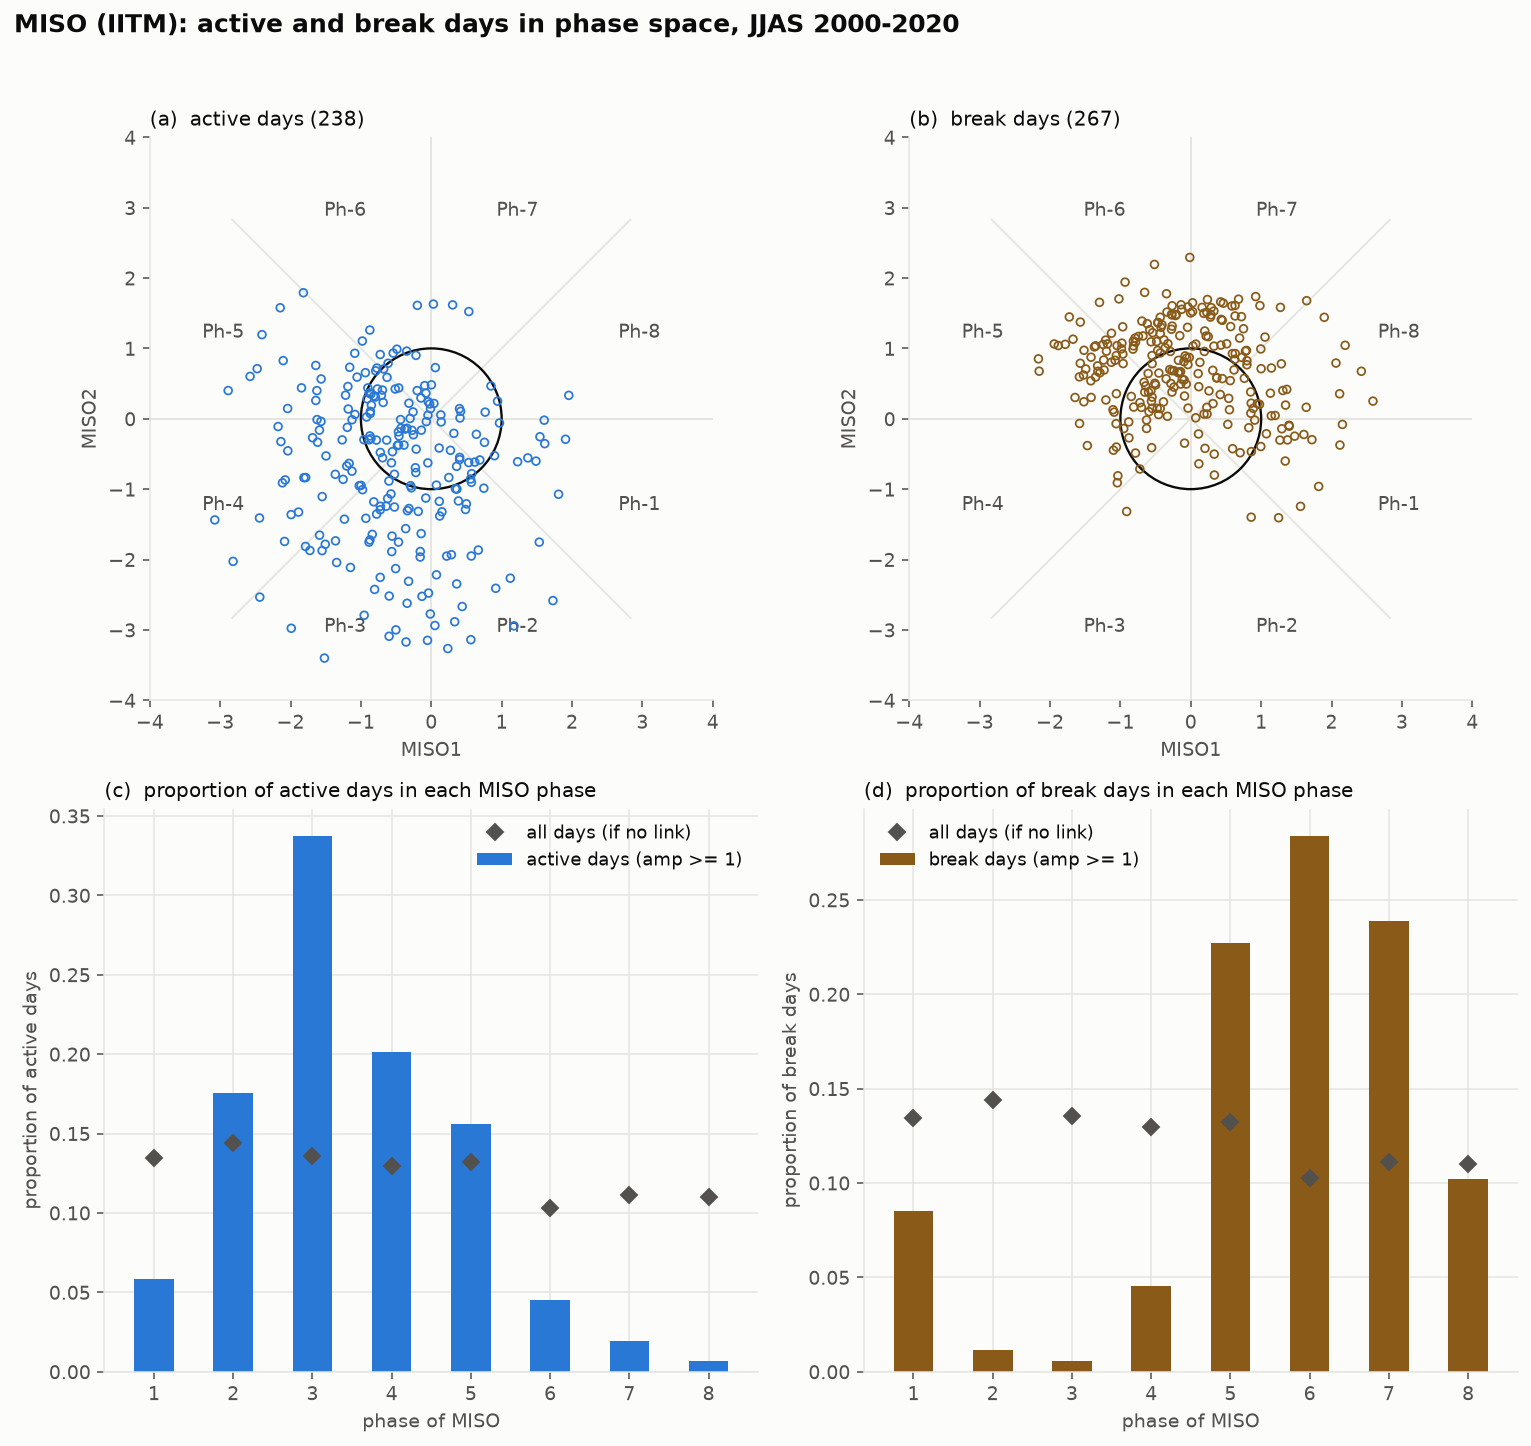

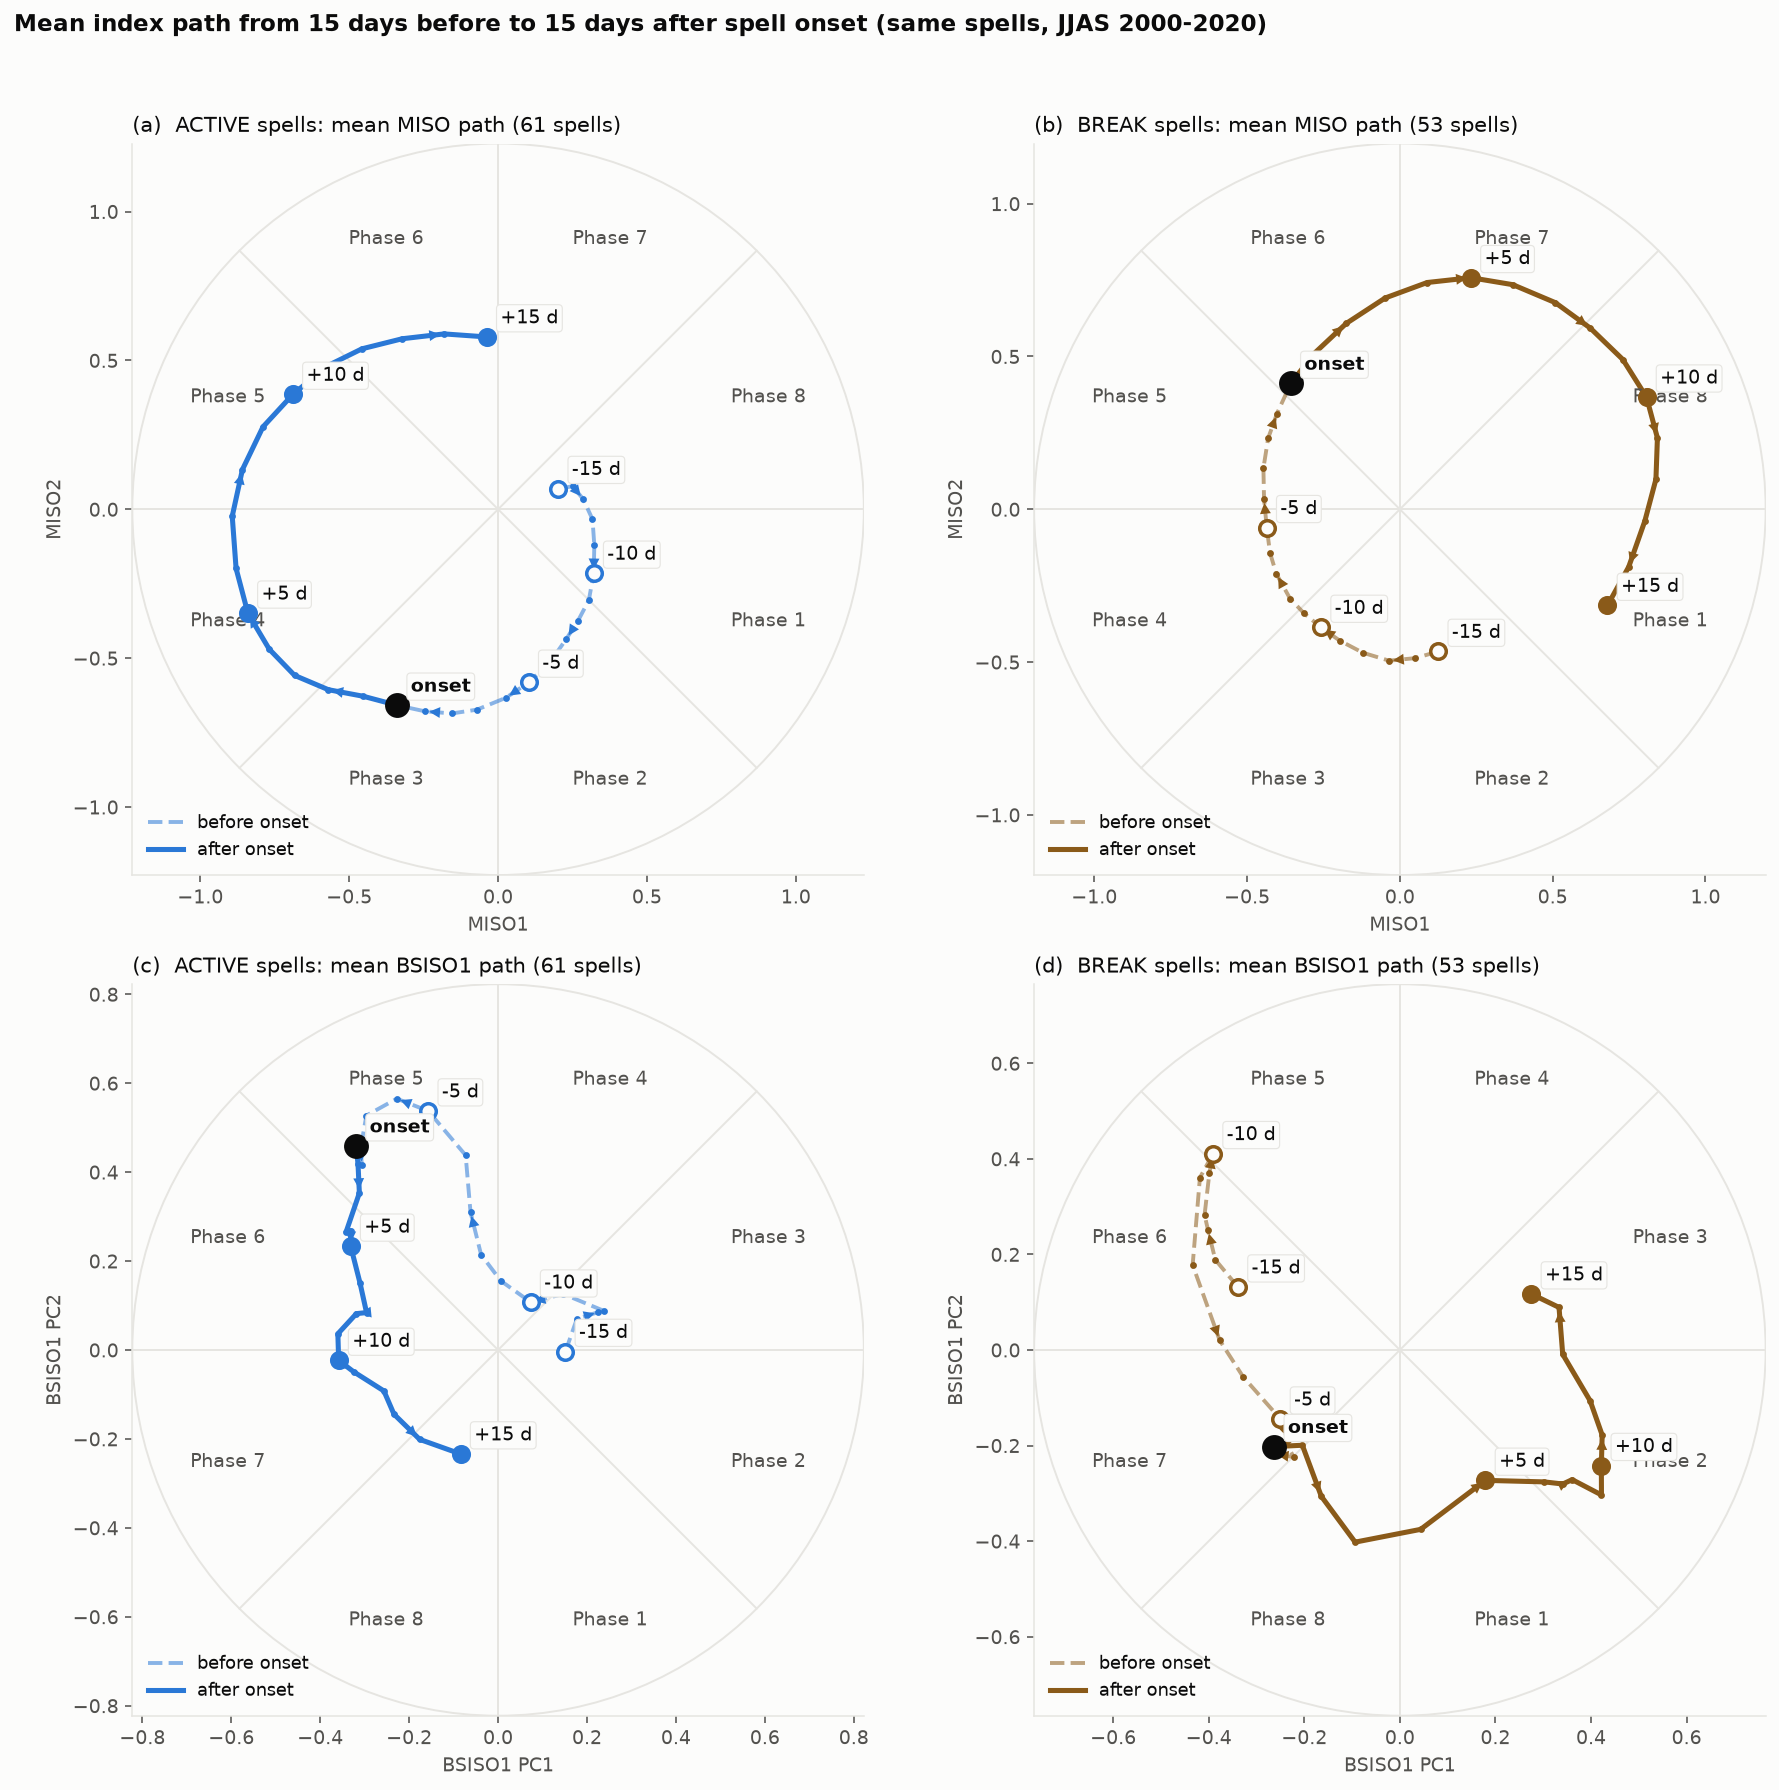

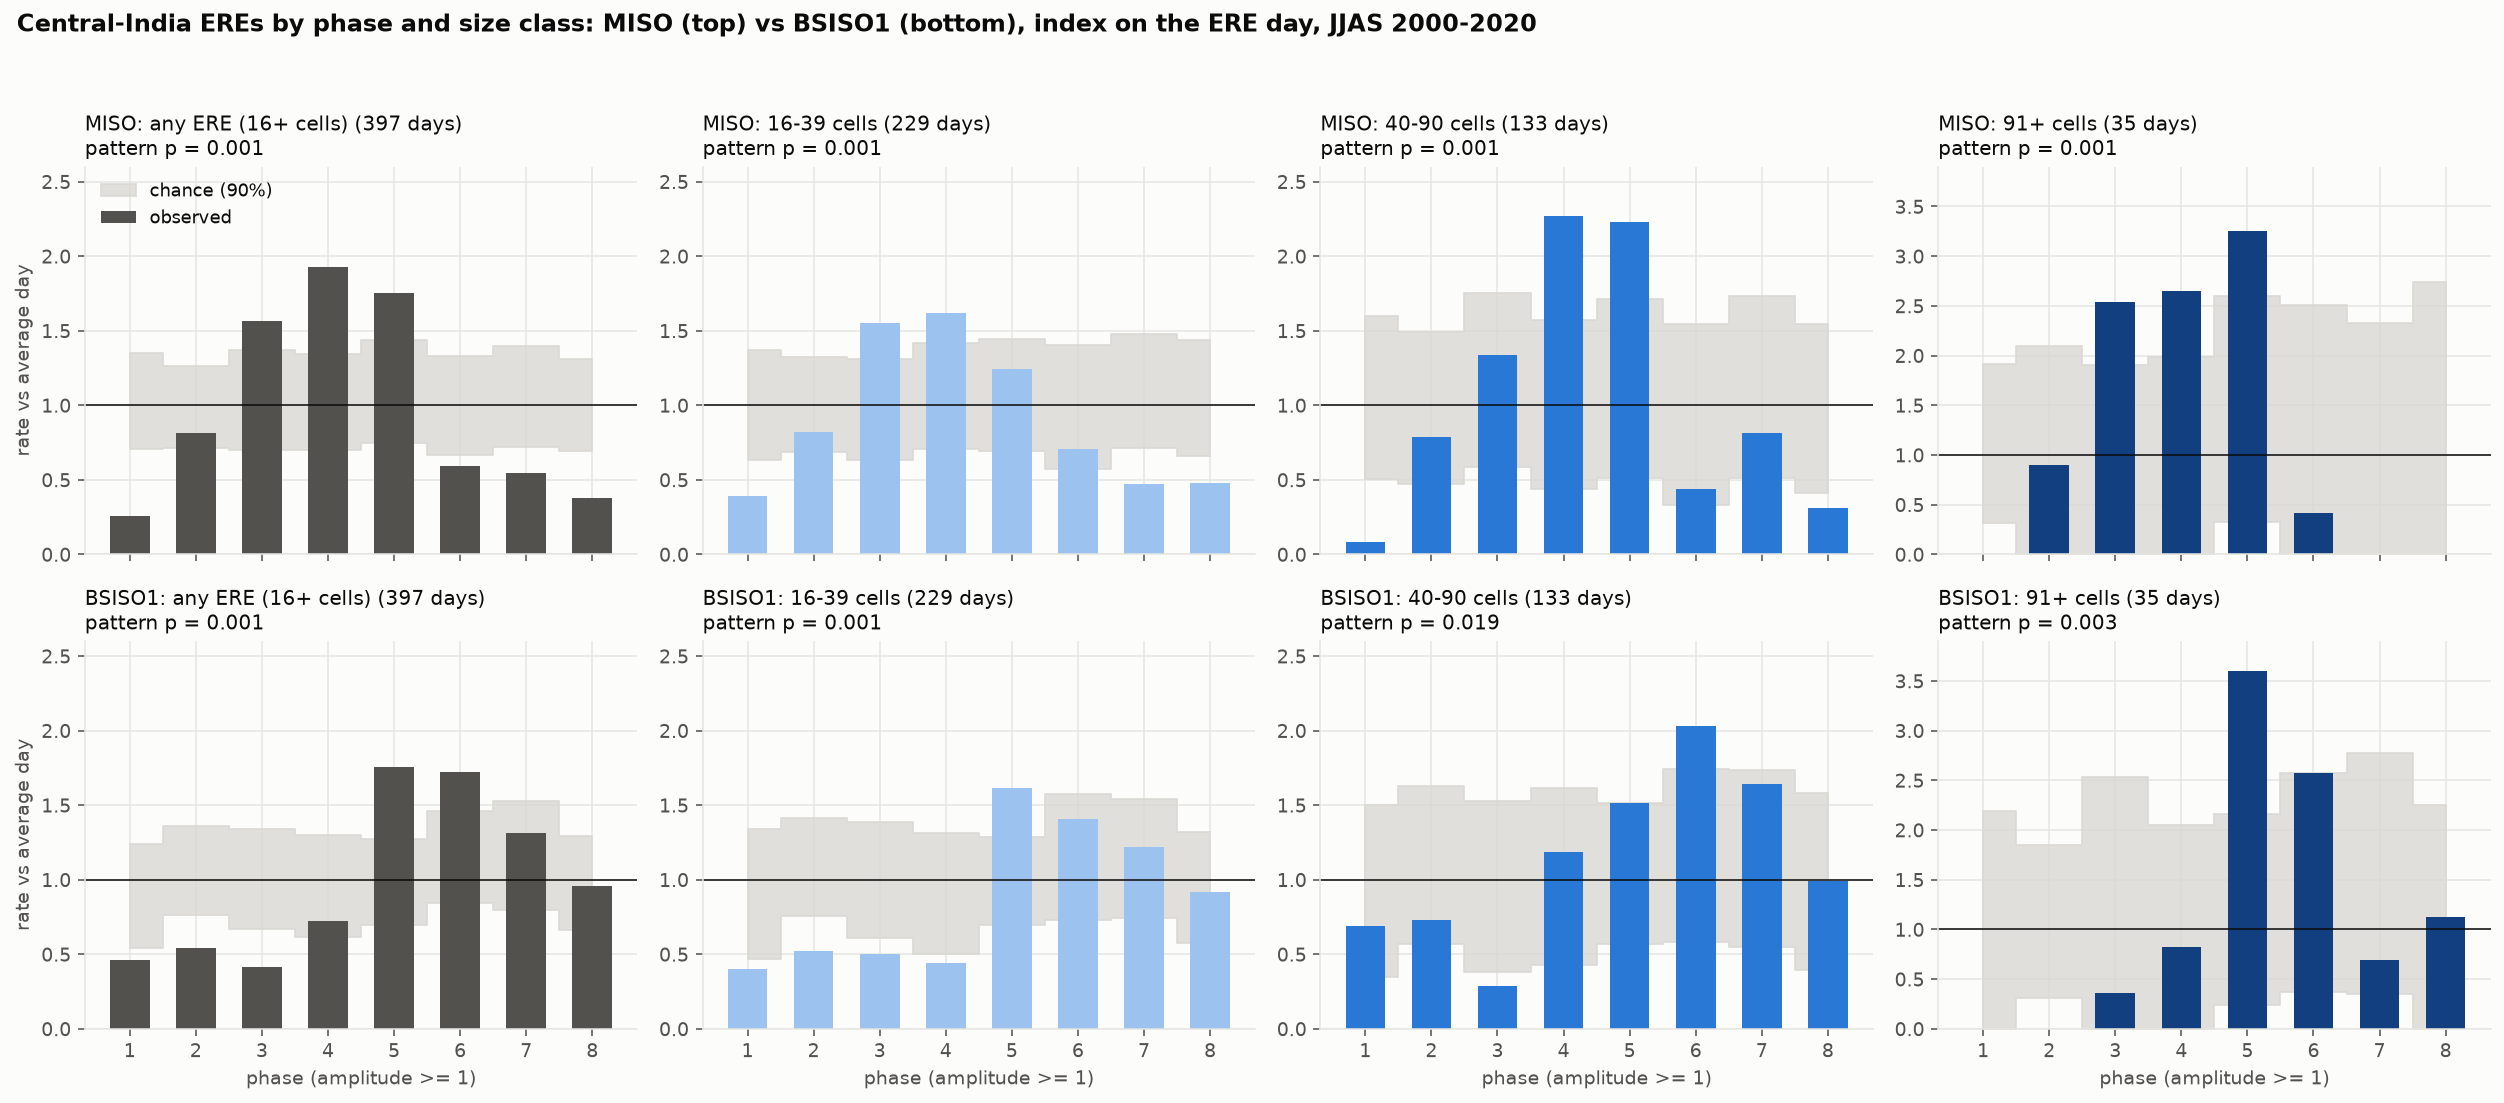

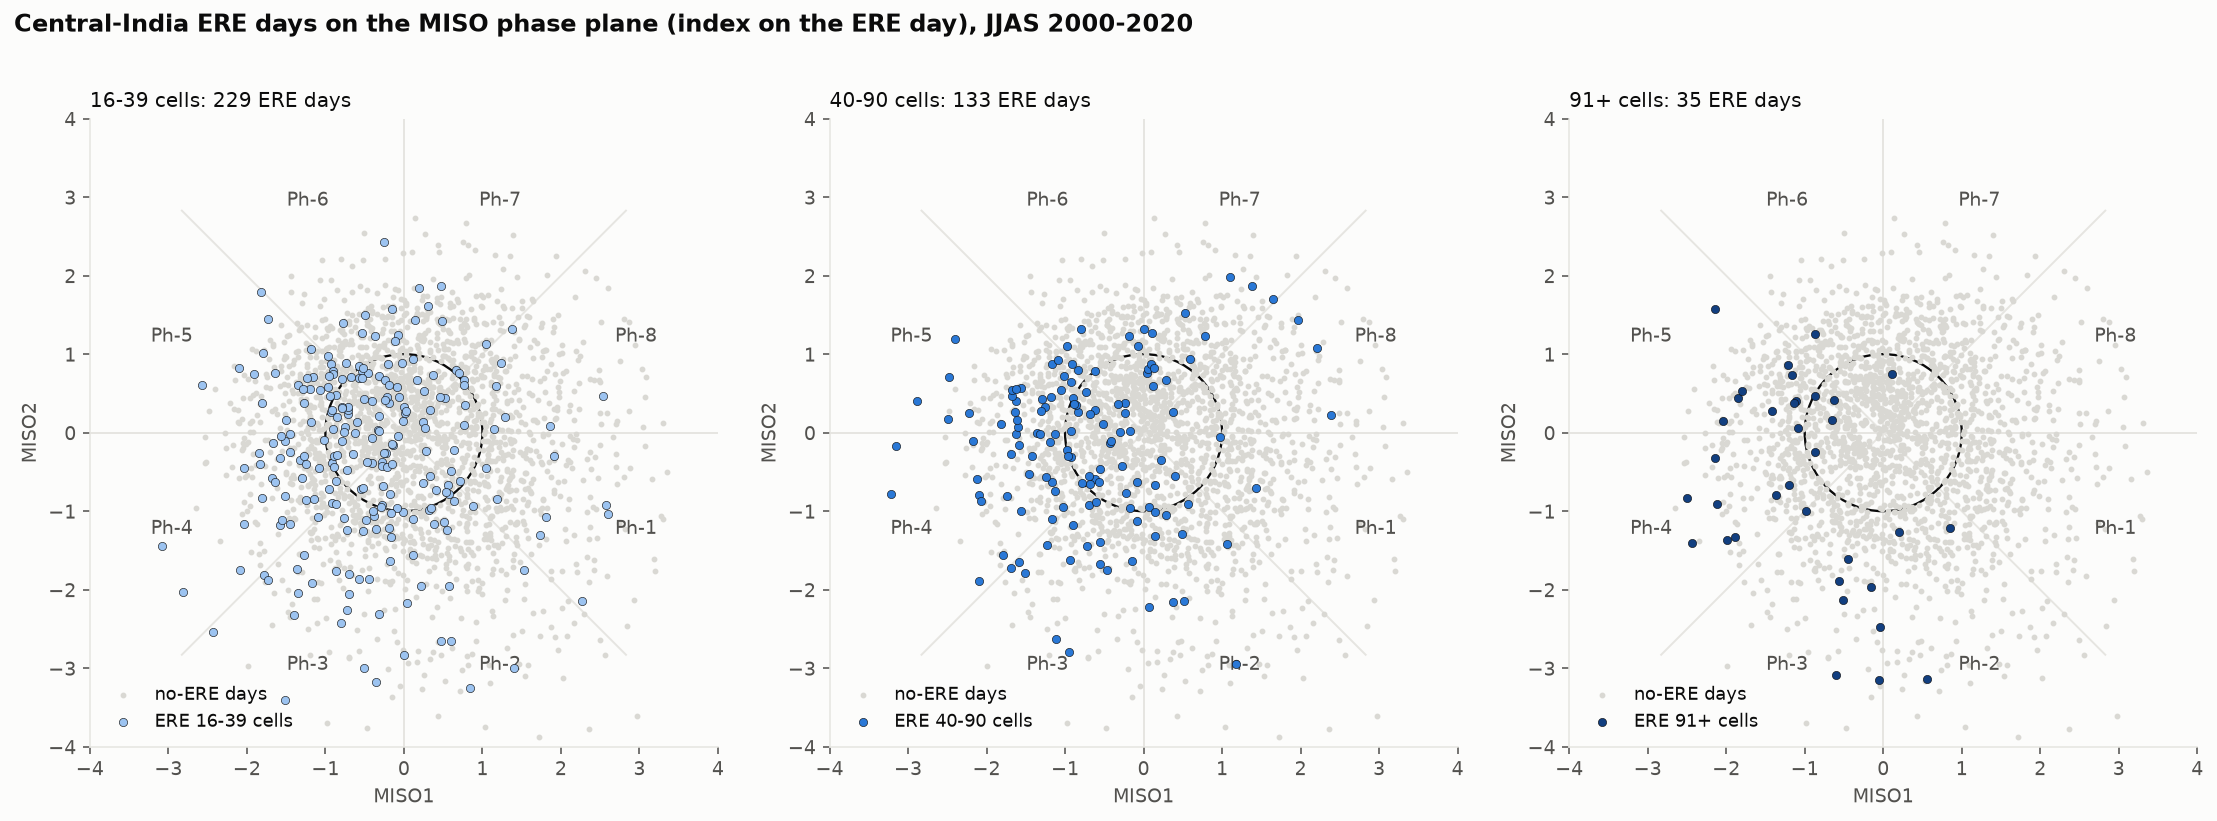

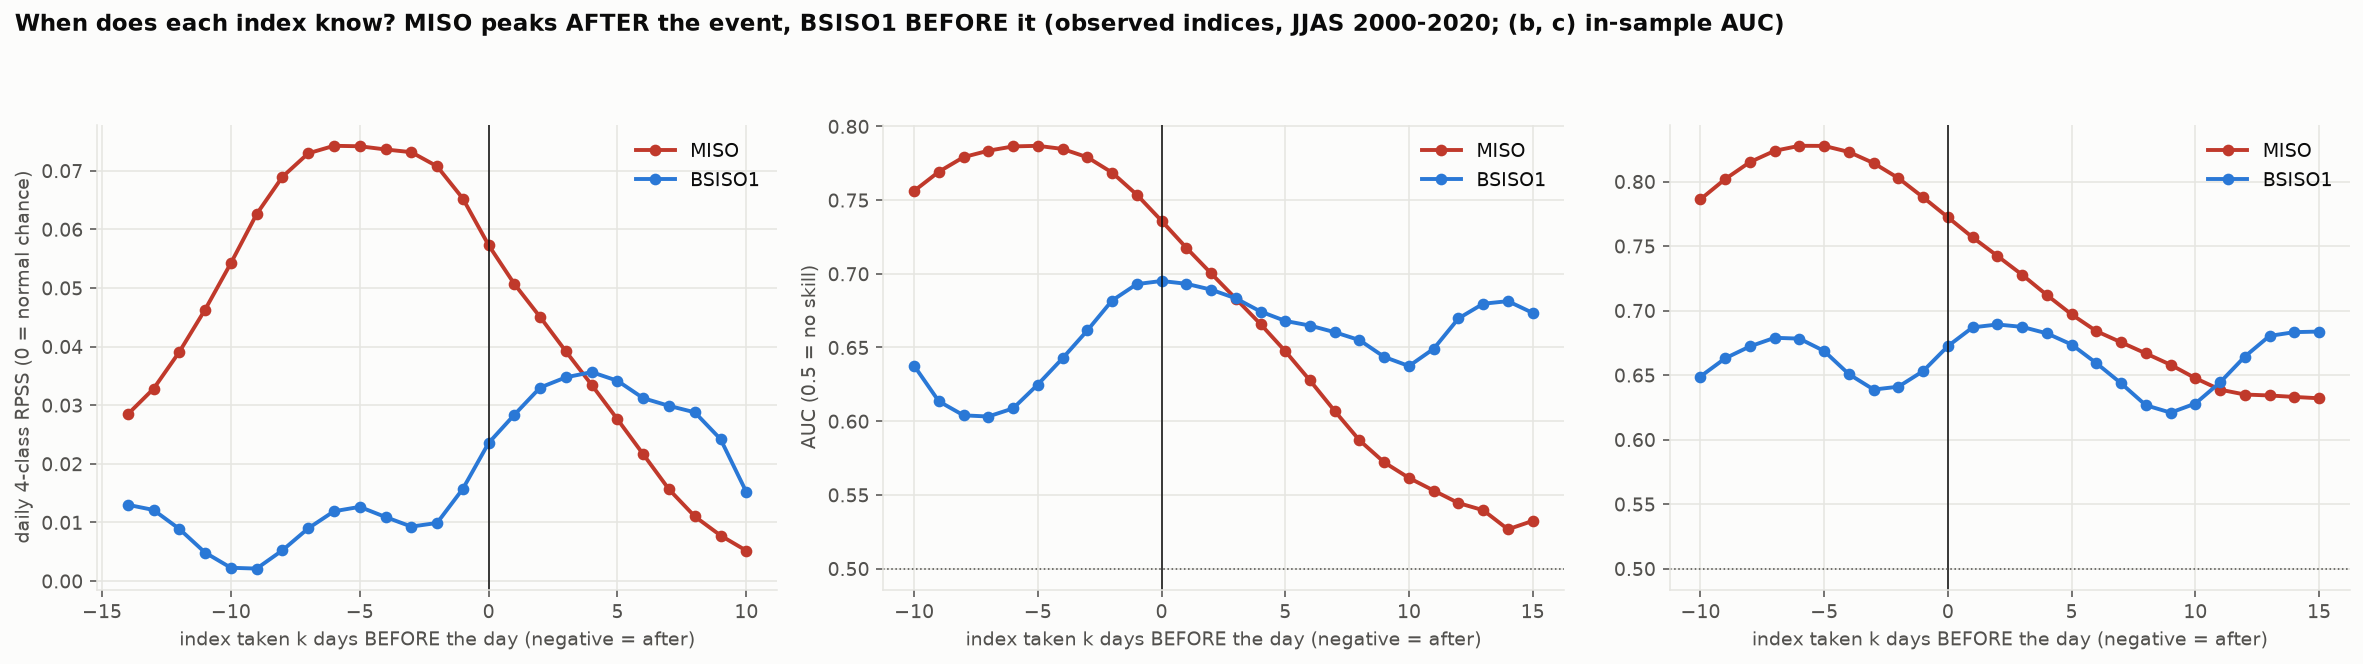

In [5]:
for f in ("fig1_spell_days_phase_space_miso.png", "fig2_index_path_around_spell_onset.png", "fig3_ere_rate_by_phase_and_class.png",
          "fig4_ere_days_miso_phase_plane.png", "fig5_when_does_the_index_know.png"):
    display(Image(os.path.join(FIGURES, f), width=1000))

## 4. Forecasting: the same transformer forecasts BSISO or MISO, then the rain step turns it into ERE chances

Simple figures: at most 4 lines each, one score per plot.

In [6]:
# Simple, readable MISO vs BSISO figures and tables (at most 4 lines per plot, one score per plot).
# Reads the tables already made by R8 / R8 follow-ups / R9e; computes nothing new.
# Output: sem_project_7/MISO_vs_BSISO_results/simple/  (S1-S6 png + MISO_vs_BSISO_simple_tables.md)
import os, matplotlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

OUT = FIGURES
os.makedirs(OUT, exist_ok=True)
rd = lambda p: pd.read_csv(os.path.join(RESULTS, os.path.basename(p)))
BL, OR, GR, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#8c8b86", "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
                     "axes.titlelocation": "left", "axes.titlesize": 15, "axes.titleweight": "bold",
                     "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.fontsize": 12, "lines.linewidth": 2.5})


def end_label(ax, x, y, text, dy=0):
    ax.annotate(text, (x[-1], y[-1]), xytext=(8, dy), textcoords="offset points", va="center", fontsize=12, color=INK)


def save(fig, name, note=None):
    if note:
        fig.text(0.01, -0.01, note, fontsize=10.5, color=INK2, ha="left", va="top")
    fig.savefig(os.path.join(OUT, name), dpi=150, bbox_inches="tight")
    plt.close(fig)


# ---------------------------------------------------------------- S1: how far ahead does each index forecast itself
IX = rd("bsiso_forecast_tests/R8/R8_index_scores.csv")
S1 = [("MISO T", OR, "-", "MISO forecast"), ("BSISO T", BL, "-", "BSISO forecast"),
      ("persistence MISO", OR, "--", "MISO persistence"), ("persistence BSISO", BL, "--", "BSISO persistence")]
fig, ax = plt.subplots(figsize=(10, 5.5))
for m, c, ls, lab in S1:
    d = IX[IX.model == m].sort_values("lead")
    ax.plot(d.lead, d.correlation, color=c, ls=ls, label=lab)
ax.axhline(0.5, color=INK2, lw=1, ls=":"); ax.text(1, 0.52, "useful (ACC 0.5)", fontsize=11, color=INK2)
ax.axhline(0, color=INK2, lw=1)
ax.set(xlabel="forecast lead (days)", ylabel="ACC (forecast vs observed index)", xlim=(1, 20.5), xticks=[1, 5, 10, 15, 20])
ax.set_title("1. MISO forecasts itself much further ahead than BSISO")
ax.legend(frameon=False, loc="lower left")
save(fig, "S1_index_forecast_ACC.png", "Same network (transformer), same days (May-Oct 1998-2020). ACC 0.5 reached at: MISO 13.4 d, BSISO 6.2 d.")

# ---------------------------------------------------------------- S2: daily ERE skill
RS = rd("bsiso_forecast_tests/R8/R8_rain_scores.csv")
S2 = [("true MISO (target day)", OR, "--", "perfect MISO on the ERE day (needs the future)"),
      ("true BSISO1 (5 d before)", BL, "--", "perfect BSISO 5 days before"),
      ("MISO T", OR, "-", "MISO forecast"), ("BSISO T", BL, "-", "BSISO forecast")]
fig, ax = plt.subplots(figsize=(10, 5.5))
for m, c, ls, lab in S2:
    d = RS[RS.model == m].sort_values("lead")
    ax.plot(d.lead, d.RPSS, color=c, ls=ls, label=lab, marker="o" if ls == "-" else None, ms=7)
ax.axhline(0, color=INK2, lw=1)
ax.set(xlabel="rain lead (days)", ylabel="RPSS (0 = normal chance)", xticks=range(1, 15), ylim=(-0.005, 0.092))
ax.set_title("2. Daily ERE skill: MISO only wins in the first ~4 days")
ax.legend(frameon=False, loc="upper right")
save(fig, "S2_daily_ERE_RPSS.png", "Central-India ERE, 4 size classes, JJAS 2000-2020 (2,562 days). At 8 d: MISO forecast 0.022 worse than BSISO "
     "[90% range -0.033, -0.012].")

# ---------------------------------------------------------------- S3: weekly ERE skill
WS = rd("R8_miso/compare/weekly_scores.csv")
fig, ax = plt.subplots(figsize=(9, 5.5))
wins = ["week 1 (days 1-7)", "week 2 (days 8-14)"]
for i, (m, c, lab) in enumerate((("BSISO T", BL, "BSISO forecast"), ("MISO T", OR, "MISO forecast"))):
    v = [WS[(WS.window == w) & (WS.model == m)]["RPSS (0/1/2+)"].iloc[0] for w in wins]
    xs = np.arange(2) + (i - 0.5) * 0.36
    ax.bar(xs, v, width=0.34, color=c, label=lab, edgecolor=SURF, linewidth=2)
    for x, y in zip(xs, v):
        ax.text(x, y + (0.003 if y >= 0 else -0.009), f"{y:.3f}", ha="center", fontsize=13)
ax.axhline(0, color=INK2, lw=1)
ax.set(xticks=range(2), xticklabels=["week 1 (days 1-7)", "week 2 (days 8-14)"], ylabel="RPSS, ERE days 0/1/2+", ylim=(-0.03, 0.13))
ax.grid(axis="x", visible=False)
ax.set_title("3. Weekly ERE skill: BSISO is better in both weeks")
ax.legend(frameon=False, loc="upper right")
save(fig, "S3_weekly_ERE_RPSS.png", "MISO minus BSISO: week 1 -0.043 [-0.069, -0.016], week 2 -0.048 [-0.081, -0.016].")

# ---------------------------------------------------------------- S4: when does each index know about the ERE
LL = rd("R8_miso/ceiling/lead_lag_minus14_to_10.csv")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axvspan(-14.5, 0, color=GRID, alpha=0.5, lw=0)
ax.text(-14.2, 0.088, "<- index taken AFTER the ERE (no use for forecasting)", fontsize=11.5, color=INK2, va="top")
ax.text(0.4, 0.088, "taken BEFORE (a real warning) ->", fontsize=11.5, color=INK2, va="top")
for col, c, lab in (("MISO", OR, "MISO"), ("BSISO1", BL, "BSISO")):
    ax.plot(LL.lag, LL[col], color=c, label=lab)
    k = LL[col].idxmax()
    ax.plot(LL.lag[k], LL[col][k], "o", color=c, ms=9, mec=SURF, mew=2)
    when = f"{abs(LL.lag[k])} d {'after' if LL.lag[k] < 0 else 'before'}"
    ax.annotate(f"{lab} best: {when}", (LL.lag[k], LL[col][k]), xytext=(14, 6), textcoords="offset points",
                ha="left", fontsize=12)
ax.axvline(0, color=INK2, lw=1)
ax.set(xlabel="days the observed index is taken before the ERE day (negative = after)", ylabel="RPSS (0 = normal chance)",
       xlim=(-14.5, 10.5), ylim=(0, 0.09), xticks=range(-14, 11, 2))
ax.set_title("4. MISO knows about EREs after they happen; BSISO before")
ax.legend(frameon=False, loc="center right")
save(fig, "S4_when_does_the_index_know.png", "Observed indices (no forecast), JJAS 2000-2020. MISO is a 15-day trailing summary of rain.")

# ---------------------------------------------------------------- S5: spell warning
SP = rd("R8_miso/spell_check/spell_lead_lag.csv")
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, sp in zip(axs, ("active", "break")):
    ax.axvspan(-10.5, 0, color=GRID, alpha=0.5, lw=0)
    for ix, c, lab in (("MISO", OR, "MISO"), ("BSISO1", BL, "BSISO")):
        d = SP[(SP.spell == sp) & (SP["index"] == ix)].sort_values("lag (+ = before)")
        ax.plot(d["lag (+ = before)"], d["AUC in-sample"], color=c, label=lab)
    ax.axhline(0.5, color=INK2, lw=1, ls=":")
    ax.axvline(0, color=INK2, lw=1)
    ax.set(xlabel="days before the spell day (negative = after)", xlim=(-10.5, 10.5), xticks=range(-10, 11, 5), ylim=(0.45, 0.9))
    ax.set_title(f"{sp} spells")
axs[0].set_ylabel("AUC (0.5 = coin flip)")
axs[0].text(-10, 0.47, "after", fontsize=11, color=INK2); axs[0].text(6.5, 0.47, "before", fontsize=11, color=INK2)
axs[0].legend(frameon=False, loc="upper right")
fig.suptitle("5. Spells: MISO is strongest once the spell has started; ahead of it the gap shrinks", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 0.93))
save(fig, "S5_spell_AUC.png", "Dey spell rule, IMERG central India 2000-2020. In-sample AUC (leave-one-year-out is lower, ~0.5 for MISO 5 d before).")

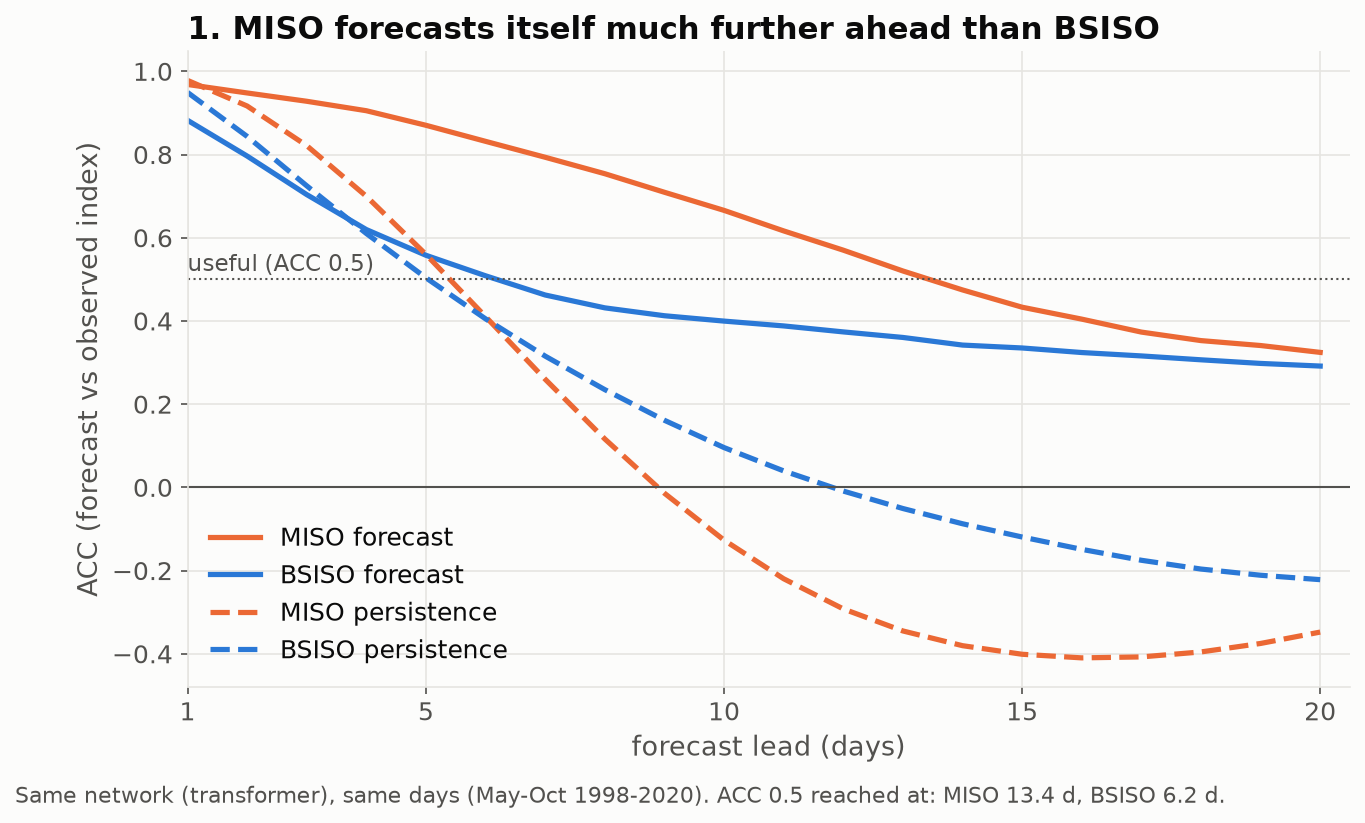

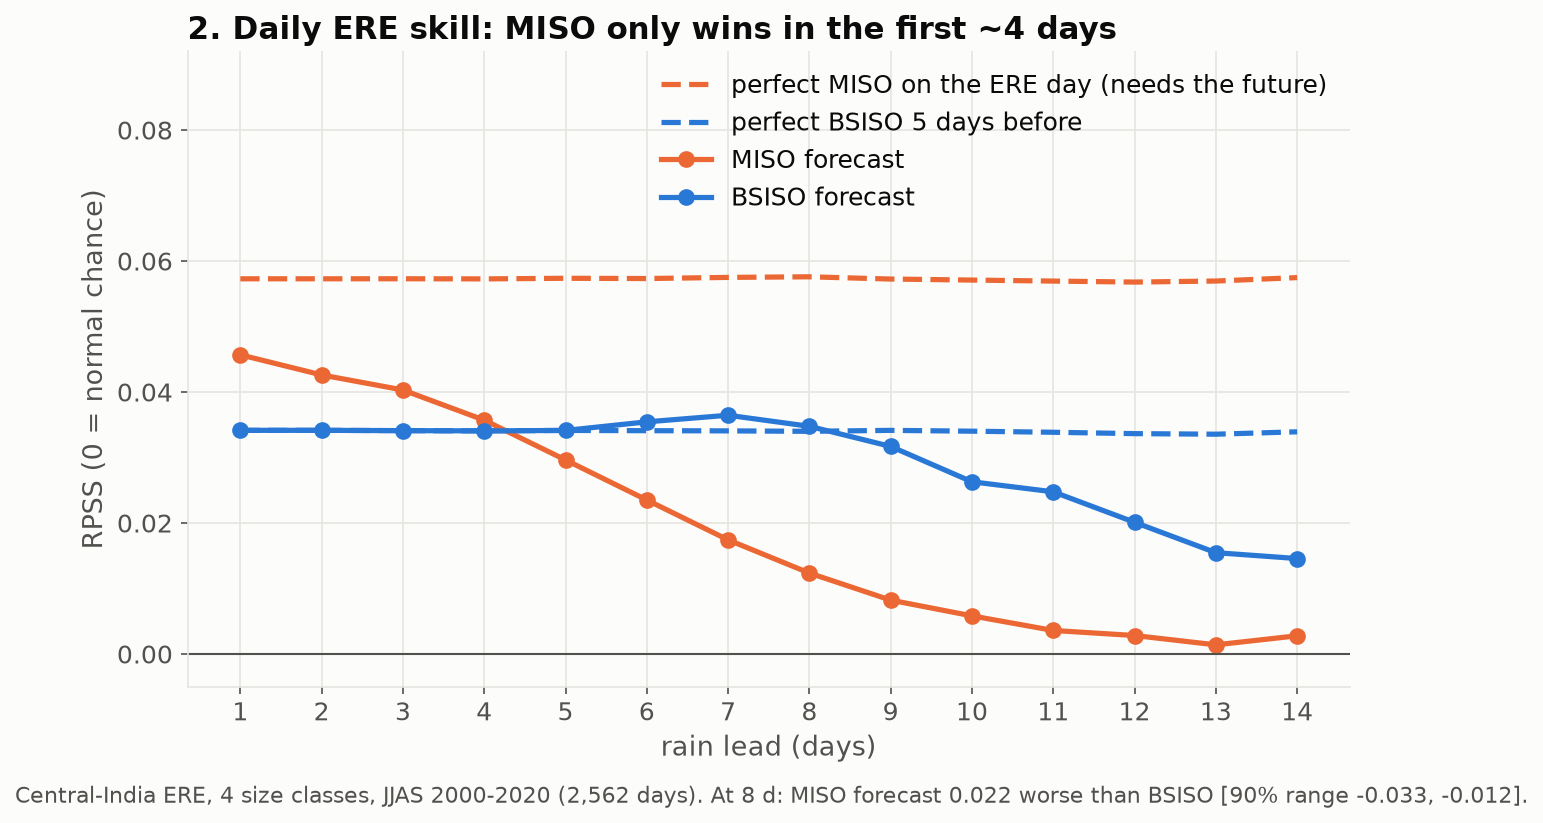

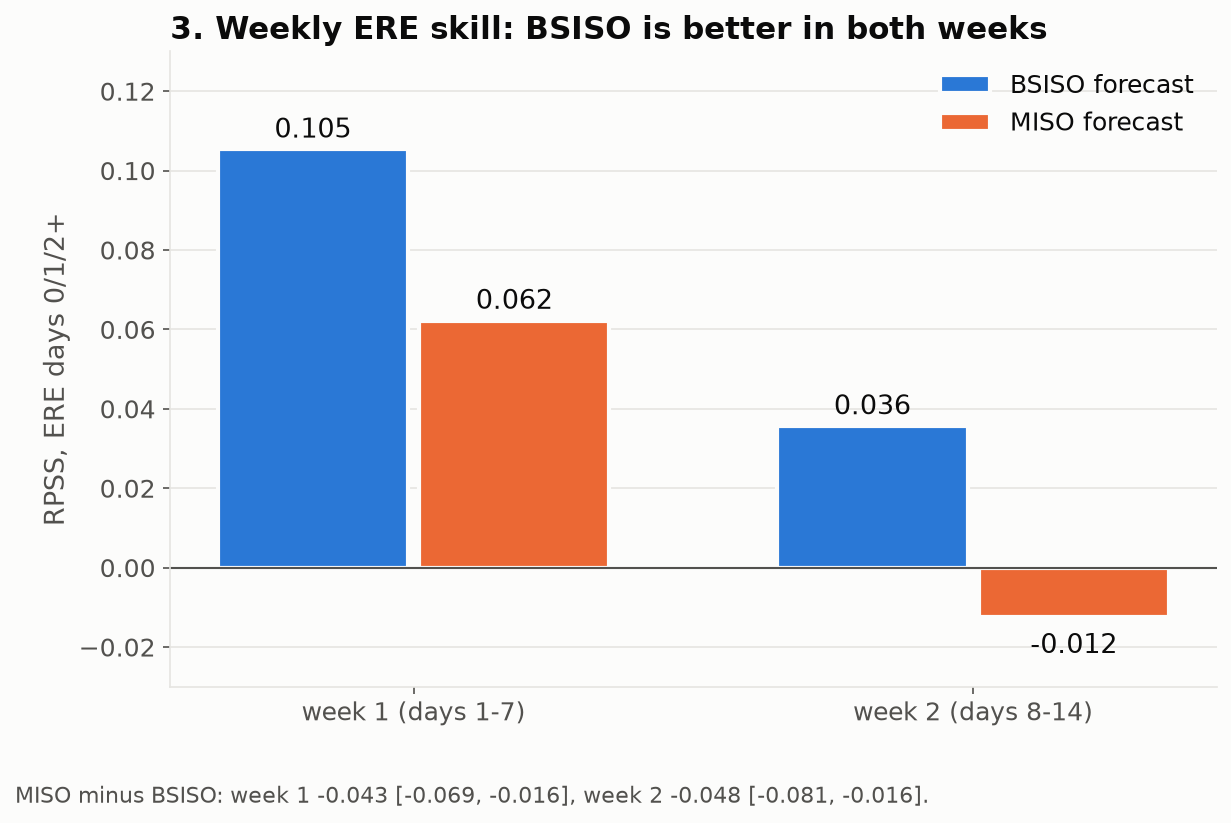

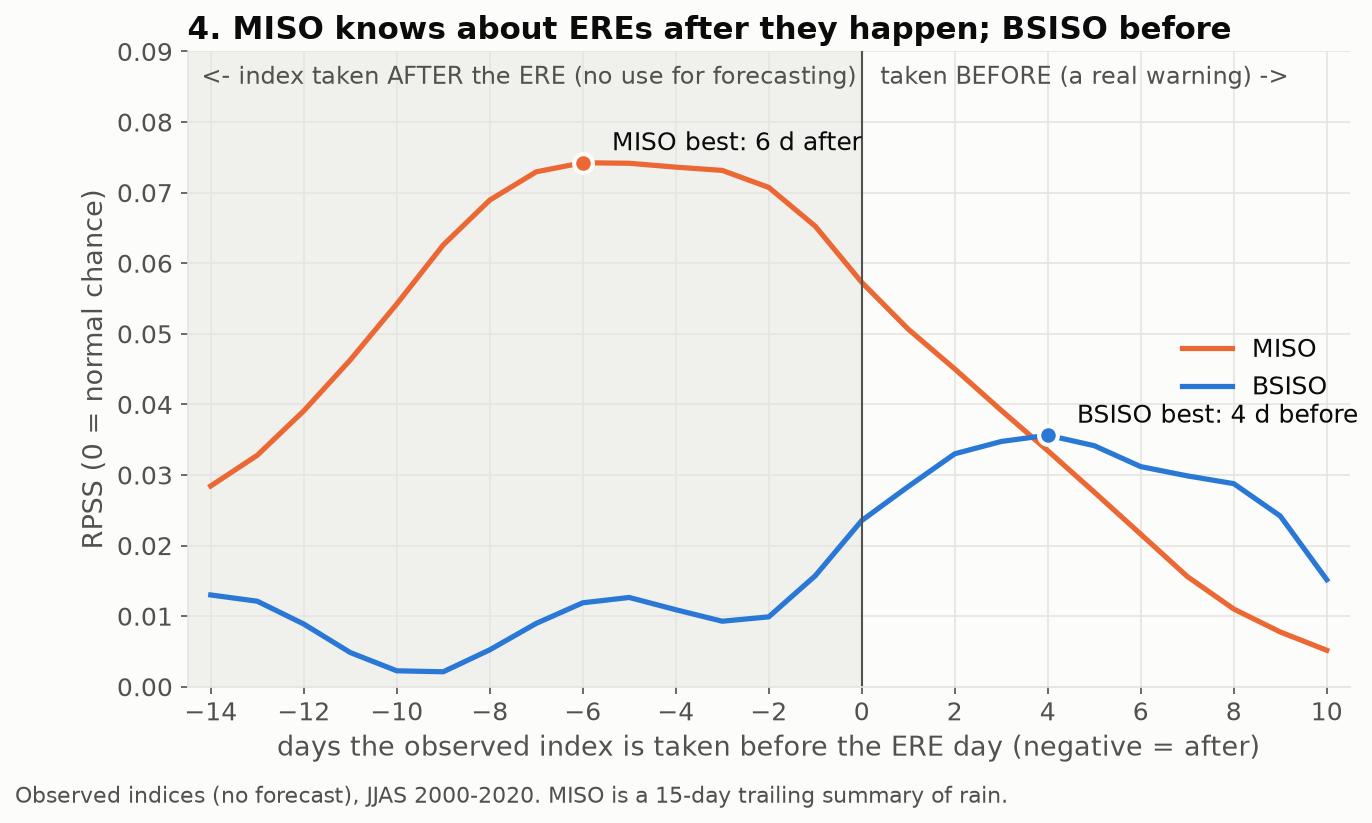

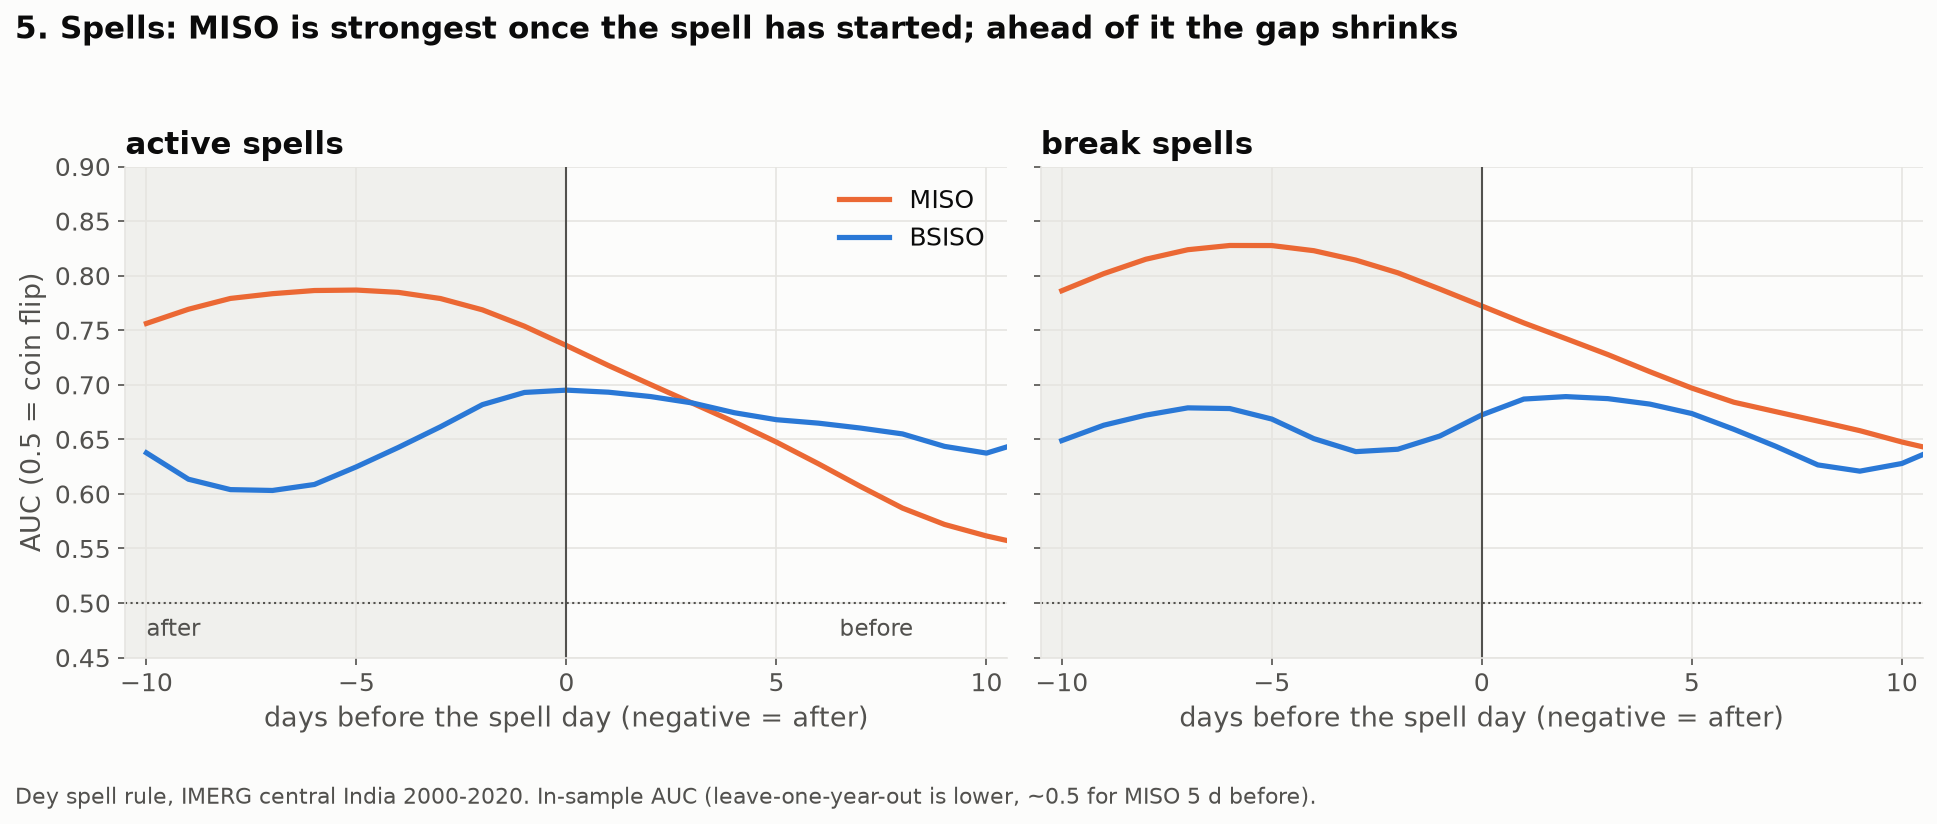

In [7]:
for f in ("S1_index_forecast_ACC.png", "S2_daily_ERE_RPSS.png", "S3_weekly_ERE_RPSS.png", "S4_when_does_the_index_know.png", "S5_spell_AUC.png"):
    display(Image(os.path.join(FIGURES, f), width=900))

In [8]:
import pandas as pd
pd.set_option("display.width", 200)
IX = pd.read_csv(os.path.join(RESULTS, "R8_index_scores.csv"))
print("ACC of each index forecast (same network, same days)")
print(IX[IX.model.isin(["BSISO T", "MISO T", "persistence BSISO", "persistence MISO"]) & IX.lead.isin([5, 10, 15, 20])]
      .pivot(index="model", columns="lead", values="correlation").round(3).to_string())
RS = pd.read_csv(os.path.join(RESULTS, "R8_rain_scores.csv"))
for c in ("RPSS", "AUC", "corr"):
    print(f"\nDaily ERE {c}")
    print(RS[RS.model.isin(["BSISO T", "MISO T"]) & RS.lead.isin([1, 3, 5, 8, 10, 14])].pivot(index="model", columns="lead", values=c).round(3).to_string())

ACC of each index forecast (same network, same days)
lead                  5      10     15     20
model                                        
BSISO T            0.558  0.400  0.335  0.292
MISO T             0.870  0.666  0.433  0.324
persistence BSISO  0.504  0.096 -0.119 -0.222
persistence MISO   0.560 -0.127 -0.401 -0.348

Daily ERE RPSS
lead        1      3      5      8      10     14
model                                            
BSISO T  0.034  0.034  0.034  0.035  0.026  0.015
MISO T   0.046  0.040  0.030  0.012  0.006  0.003

Daily ERE AUC
lead        1      3      5      8      10    14
model                                           
BSISO T  0.681  0.678  0.673  0.659  0.630  0.59
MISO T   0.693  0.676  0.647  0.604  0.584  0.57

Daily ERE corr
lead        1      3      5      8      10     14
model                                            
BSISO T  0.228  0.225  0.220  0.219  0.186  0.139
MISO T   0.258  0.239  0.204  0.143  0.113  0.090
